In [1]:
!nvidia-smi

Mon Nov 23 09:25:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.5     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H200                    On  |   00000000:DF:00.0 Off |                   On |
| N/A   34C    P0             78W /  700W |                  N/A   |     N/A      Default |
|                                         |                        |              Enabled |
+-----------------------------------------+-----

In [2]:
!nproc


224


In [3]:
!cat /sys/fs/cgroup/memory.max

34359738368


In [4]:
!df -h /dev/shm /workspace


Filesystem      Size  Used Avail Use% Mounted on
tmpfs           6.0G     0  6.0G   0% /dev/shm
/dev/md1        1.8T   95G  1.7T   6% /workspace


In [5]:
!pwd

/workspace/seg_project


In [6]:
!cd /workspace/seg_project/


In [7]:
!pip install roboflow

import os
from dotenv import load_dotenv
from roboflow import Roboflow

load_dotenv("/workspace/seg_project/.env")
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
project = rf.workspace("duppalapudis-workspace").project("semnatic_segmenation_project")
version = project.version(2)
dataset = version.download("png-mask-semantic", location="/workspace/seg_project/data/roboflow_v2")
                

loading Roboflow workspace...
loading Roboflow project...


In [8]:
!ls

checkpoints  data  logs  outputs  segmentation_u-net_plus_vit.ipynb


In [9]:
!ls -la /workspace/seg_project/data
!ls /workspace/seg_project/semnatic_segmenation_project-2

total 0
drwxr-xr-x 4 root root  47 Nov 23 08:19 .
drwxr-xr-x 7 root root 143 Nov 23 09:25 ..
drwxr-xr-x 5 root root  44 Nov 23 08:19 processed_1024
drwxr-xr-x 5 root root  71 Nov 23 07:12 roboflow_v2
ls: cannot access '/workspace/seg_project/semnatic_segmenation_project-2': No such file or directory


In [10]:
#Look at what files are in the folder.
from pathlib import Path
import shutil

BASE = Path("/workspace/seg_project")
src  = BASE / "semnatic_segmenation_project-2"
dst  = BASE / "data" / "roboflow_v2"

# create the remaining project folders
for d in ["logs", "outputs/metrics", "outputs/overlays"]:
    (BASE / d).mkdir(parents=True, exist_ok=True)

# move the dataset into data/roboflow_v2
if src.exists() and not dst.exists():
    shutil.move(str(src), str(dst))

# shared paths for every later cell
DATA_ROOT = dst
CKPT_DIR  = BASE / "checkpoints"
LOG_DIR   = BASE / "logs"
OUT_DIR   = BASE / "outputs"

print("data/roboflow_v2:", sorted(p.name for p in DATA_ROOT.iterdir()))
print("old folder gone:", not src.exists())
for s in ["train", "valid", "test"]:
    n = len(list((DATA_ROOT / s).glob("*")))
    print(f"{s}: {n} files")

data/roboflow_v2: ['README.roboflow.txt', 'test', 'train', 'valid']
old folder gone: True
train: 3839 files
valid: 839 files
test: 807 files


In [11]:
#Read the list that says "number 0 = this class name, number 1 = that class name."
from getpass import getpass
from pathlib import Path
import os

env_path = Path("/workspace/seg_project/.env")
key = getpass("Paste your NEW Roboflow API key: ")
env_path.write_text(f"ROBOFLOW_API_KEY={key}\n")
os.chmod(env_path, 0o600)   # only the owner can read it
del key
print("saved:", env_path)

Paste your NEW Roboflow API key:  ········


saved: /workspace/seg_project/.env


In [12]:
!ls -la /workspace/seg_project/.env
from dotenv import load_dotenv; import os
load_dotenv("/workspace/seg_project/.env")
print("key loaded:", len(os.environ.get("ROBOFLOW_API_KEY", "")), "characters")

-rw------- 1 root root 38 Nov 23 09:26 /workspace/seg_project/.env
key loaded: 20 characters


In [13]:
!pip install -q segmentation-models-pytorch timm albumentations opencv-python-headless matplotlib tqdm

import torch, cv2, numpy as np
import albumentations as A
import segmentation_models_pytorch as smp
import timm

print("torch :", torch.__version__)
print("cv2   :", cv2.__version__)
print("numpy :", np.__version__)
print("albu  :", A.__version__)
print("smp   :", smp.__version__)
print("timm  :", timm.__version__)

# CUDA check
assert torch.cuda.is_available(), "CUDA not available"
props = torch.cuda.get_device_properties(0)
print("\nGPU   :", torch.cuda.get_device_name(0), f"| {props.total_memory/1e9:.1f} GB")
print("CUDA  :", torch.version.cuda)

# bfloat16 check
print("bf16 supported:", torch.cuda.is_bf16_supported())
x = torch.randn(1024, 1024, device="cuda", dtype=torch.bfloat16)
y = x @ x
print("bf16 matmul OK:", y.dtype, y.shape)

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


torch : 2.15.0a0+fd23299d96.nv26.11
cv2   : 5.1.0
numpy : 2.1.0
albu  : 2.0.8
smp   : 0.6.0
timm  : 1.0.31

GPU   : NVIDIA H200 MIG 3g.71gb | 74.9 GB
CUDA  : 13.5
bf16 supported: True
bf16 matmul OK: torch.bfloat16 torch.Size([1024, 1024])


In [14]:
#Look at what files are in the folder.
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, cv2

BASE      = Path("/workspace/seg_project")
DATA_ROOT = BASE / "data" / "roboflow_v2"
CKPT_DIR, LOG_DIR, OUT_DIR = BASE / "checkpoints", BASE / "logs", BASE / "outputs"

print("Top level:", sorted(p.name for p in DATA_ROOT.iterdir()))
print("Sample files in train:", sorted(p.name for p in (DATA_ROOT / "train").iterdir())[:6])

Top level: ['README.roboflow.txt', 'test', 'train', 'valid']
Sample files in train: ['10003_jpg.rf.36c75615048e0cccd8aa6bedc9867ed2.jpg', '10003_jpg.rf.36c75615048e0cccd8aa6bedc9867ed2_mask.png', '10006_jpg.rf.9c3a974c98fdb91444289d0d42cea0df.jpg', '10006_jpg.rf.9c3a974c98fdb91444289d0d42cea0df_mask.png', '10009_jpg.rf.82a642a1f5e79e440dfd78e577803cb9.jpg', '10009_jpg.rf.82a642a1f5e79e440dfd78e577803cb9_mask.png']


In [15]:
#Read the list that says "number 0 = this class name, number 1 = that class name."
csv_path = next(DATA_ROOT.rglob("_classes.csv"))
classes = pd.read_csv(csv_path)
classes.columns = [c.strip() for c in classes.columns]
print(csv_path)
print(classes)

/workspace/seg_project/data/roboflow_v2/train/_classes.csv
   Pixel Value           Class
0            0      background
1            1   auto_rickshaw
2            2             bus
3            3             car
4            4             cng
5            5          leguna
6            6      motorcycle
7            7           truck


In [16]:
# Match each photo with its mask and make sure none is missing#
IMG_EXT = {".jpg", ".jpeg", ".png"}
splits, problems = {}, []

for split in ["train", "valid", "test"]:
    d = DATA_ROOT / split
    imgs = sorted(p for p in d.iterdir()
                  if p.suffix.lower() in IMG_EXT and not p.stem.endswith("_mask"))
    pairs = []
    for img in imgs:
        mask = d / f"{img.stem}_mask.png"
        if mask.exists():
            pairs.append((img, mask))
        else:
            problems.append(f"missing mask: {img.name}")
    splits[split] = pairs
    print(f"{split}: {len(imgs)} images, {len(pairs)} paired")

train: 1919 images, 1919 paired
valid: 419 images, 419 paired
test: 403 images, 403 paired


In [17]:
#Open every mask and check the numbers inside are sensible (0, 1, 2...) and the mask is the same size as its photo.
pixel_counts, per_split_values, sizes = Counter(), {}, Counter()

for split, pairs in splits.items():
    vals = set()
    for img, mask in pairs:
        m  = cv2.imread(str(mask), cv2.IMREAD_UNCHANGED)
        im = cv2.imread(str(img))
        if m is None or im is None:
            problems.append(f"unreadable: {img.name}"); continue
        if m.ndim != 2:
            problems.append(f"mask not single-channel: {mask.name} {m.shape}"); continue
        if m.shape != im.shape[:2]:
            problems.append(f"size mismatch: {img.name}"); continue
        u, c = np.unique(m, return_counts=True)
        pixel_counts.update(dict(zip(u.tolist(), c.tolist())))
        vals.update(u.tolist())
        sizes[im.shape[:2]] += 1
    per_split_values[split] = sorted(vals)

print("Problems:", len(problems)); print(problems[:10])
print("Mask values per split:", per_split_values)
print("Image sizes (H, W):", sizes.most_common(5))

Problems: 0
[]
Mask values per split: {'train': [0, 1, 2, 3, 4, 5, 6, 7], 'valid': [0, 1, 2, 3, 4, 5, 6, 7], 'test': [0, 1, 2, 3, 4, 5, 6, 7]}
Image sizes (H, W): [((720, 1280), 1009), ((3060, 4080), 977), ((963, 1280), 374), ((960, 1280), 174), ((3000, 4000), 60)]


In [18]:
#Count what share of all pixels each class takes up. This shows whether one class (like background) dominates
total = sum(pixel_counts.values())
print("Pixel value -> share of all pixels")
for k in sorted(pixel_counts):
    print(f"  {k:>3}: {pixel_counts[k]/total:.4%}")

Pixel value -> share of all pixels
    0: 82.2623%
    1: 4.5237%
    2: 2.9437%
    3: 2.5010%
    4: 0.6024%
    5: 2.9509%
    6: 1.0964%
    7: 3.1195%


In [19]:
NUM_CLASSES = len(classes)                       # 8
CLASS_NAMES = classes.sort_values("Pixel Value")["Class"].str.strip().tolist()

In [20]:
import torch
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

# Why train only? Weights are part of training. If we counted valid/test too,
# information from the exam data would leak into training.
def count_classes(mask_path):
    m = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
    # bincount counts how many pixels have value 0, 1, 2, ... 7
    return np.bincount(m.ravel(), minlength=NUM_CLASSES)

train_masks = [mask for _, mask in splits["train"]]
with ThreadPoolExecutor(16) as ex:
    counts = sum(tqdm(ex.map(count_classes, train_masks),
                      total=len(train_masks), desc="counting train pixels"))

shares = counts / counts.sum()          # share of pixels per class, adds up to 1
for name, s in zip(CLASS_NAMES, shares):
    print(f"{name:>14}: {s:.4%}")

counting train pixels: 100%|██████████| 1919/1919 [00:13<00:00, 139.48it/s]

    background: 82.2788%
 auto_rickshaw: 4.2440%
           bus: 3.0502%
           car: 2.6143%
           cng: 0.6077%
        leguna: 3.2103%
    motorcycle: 1.2647%
         truck: 2.7298%


In [21]:
# Rare class -> bigger weight. weight = 1 / sqrt(share)
# The square root keeps it gentle: cng ends up ~12x background, not ~135x.
# Huge weights would make training jumpy and unstable.
raw_w = 1.0 / np.sqrt(shares)

# Rescale so the average weight is 1. This only keeps the loss at a normal
# size. The ratios between classes stay the same.
class_weights = raw_w / raw_w.mean()
class_weights = torch.tensor(class_weights, dtype=torch.float32)

print("Class weights (higher = mistakes on this class cost more):")
for name, w in zip(CLASS_NAMES, class_weights.tolist()):
    print(f"{name:>14}: {w:.3f}")
print("average:", class_weights.mean().item())
print("cng / background ratio:", (class_weights[4] / class_weights[0]).item())

Class weights (higher = mistakes on this class cost more):
    background: 0.172
 auto_rickshaw: 0.758
           bus: 0.894
           car: 0.966
           cng: 2.004
        leguna: 0.872
    motorcycle: 1.389
         truck: 0.945
average: 1.0
cng / background ratio: 11.635784149169922


In [22]:
import torch.nn as nn
import segmentation_models_pytorch as smp

class DiceCELoss(nn.Module):
    """0.5 * Dice + 0.5 * weighted Cross-Entropy (your spec, plus CE weights)."""
    def __init__(self, class_weights, dice_w=0.5, ce_w=0.5):
        super().__init__()
        # CE looks at every pixel; the weights make rare-class mistakes cost more
        self.ce   = nn.CrossEntropyLoss(weight=class_weights)
        # Dice looks at each class as a whole shape, so it is fair to small classes
        self.dice = smp.losses.DiceLoss(mode="multiclass")
        self.dice_w, self.ce_w = dice_w, ce_w

    def forward(self, logits, target):
        # logits: (N, 8, H, W) model output | target: (N, H, W) integer class IDs
        logits = logits.float()   # compute the loss in float32 even when training in bf16
        return self.dice_w * self.dice(logits, target) + self.ce_w * self.ce(logits, target)

# Quick test with fake data
criterion = DiceCELoss(class_weights.cuda()).cuda()
fake_logits = torch.randn(2, NUM_CLASSES, 64, 64, device="cuda")
fake_target = torch.randint(0, NUM_CLASSES, (2, 64, 64), device="cuda")   # must be int64
print("loss on random data:", criterion(fake_logits, fake_target).item())

loss on random data: 1.6844151020050049


In [23]:
# ===== Cell 2f: one-time shrink of the huge photos (run once) =====
# Goal: make a smaller copy of the dataset (longest side <= 1024) so training
# loads fast. The original data in data/roboflow_v2/ is NOT changed.

from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
import cv2, numpy as np

PROC_ROOT = BASE / "data" / "processed_1024"   # where the smaller copy is saved
MAX_SIDE  = 1024                                # longest side allowed

def shrink(pair, split):
    img_p, mask_p = pair
    out = PROC_ROOT / split
    out.mkdir(parents=True, exist_ok=True)

    im = cv2.imread(str(img_p))                           # photo (3 channels)
    m  = cv2.imread(str(mask_p), cv2.IMREAD_UNCHANGED)    # mask (raw class numbers)

    s = MAX_SIDE / max(im.shape[:2])                      # scale factor
    if s < 1:                                             # only shrink, never enlarge
        new_size = (round(im.shape[1] * s), round(im.shape[0] * s))   # (width, height)
        im = cv2.resize(im, new_size, interpolation=cv2.INTER_AREA)   # smooth, good for photos
        m  = cv2.resize(m,  new_size, interpolation=cv2.INTER_NEAREST) # copies values, never blends class IDs

    cv2.imwrite(str(out / img_p.name), im, [cv2.IMWRITE_JPEG_QUALITY, 95])
    cv2.imwrite(str(out / mask_p.name), m)                # PNG = lossless, keeps exact numbers
    return np.unique(m).tolist()                          # class numbers found in this mask

seen = set()
for split, pairs in splits.items():                       # train, valid, test
    with ThreadPoolExecutor(16) as ex:                    # 16 threads = faster
        for vals in tqdm(ex.map(lambda p: shrink(p, split), pairs),
                         total=len(pairs), desc=split):
            seen.update(vals)

# Safety check: must still be exactly 0..7. A new number would mean blending happened.
print("Mask values after resize:", sorted(seen))

test: 100%|██████████| 403/403 [00:01<00:00, 223.97it/s]

Mask values after resize: [0, 1, 2, 3, 4, 5, 6, 7]


In [24]:
# ===== Cell 3a: settings + (photo, mask) lists from the SMALL copy =====
from pathlib import Path
import cv2, numpy as np, torch
from tqdm.auto import tqdm                      # progress bar for the check loop below
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

PROC_ROOT   = BASE / "data" / "processed_1024"  # smaller copy made by Cell 2f
IMG_SIZE    = 512                                # model input size (divisible by 32)
BATCH_SIZE  = 16
NUM_WORKERS = 4

# ImageNet statistics: the encoder was pretrained on ImageNet, so it expects
# photos scaled with exactly these numbers (one per R, G, B channel).
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

def list_pairs(split):
    """Return [(photo_path, mask_path), ...] for one split."""
    d = PROC_ROOT / split
    imgs = sorted(p for p in d.iterdir() if p.suffix.lower() in {".jpg", ".jpeg"})
    return [(p, d / f"{p.stem}_mask.png") for p in imgs]   # masks are .png, so they are skipped above

pairs = {s: list_pairs(s) for s in ["train", "valid", "test"]}

# Check: every photo has a mask, and the largest side is <= 1024 (proves 2f worked)
for s, plist in pairs.items():
    missing, too_big = 0, 0
    for img_p, mask_p in tqdm(plist, desc=f"check {s}"):
        if not mask_p.exists():
            missing += 1
        h, w = cv2.imread(str(img_p), cv2.IMREAD_REDUCED_COLOR_8).shape[:2]  # fast: decodes at 1/8 size
        if max(h, w) * 8 > 1032:               # x8 to undo the reduction (small tolerance)
            too_big += 1
    print(f"{s}: {len(plist)} pairs | missing masks: {missing} | still too big: {too_big}")

check train: 100%|██████████| 1919/1919 [00:04<00:00, 424.77it/s]


train: 1919 pairs | missing masks: 0 | still too big: 0


check valid: 100%|██████████| 419/419 [00:00<00:00, 436.29it/s]


valid: 419 pairs | missing masks: 0 | still too big: 0


check test: 100%|██████████| 403/403 [00:00<00:00, 429.53it/s]

test: 403 pairs | missing masks: 0 | still too big: 0


In [25]:
# ===== Cell 3b: transforms =====
# Every geometric step is applied to the photo AND the mask together,
# so they never go out of alignment.

train_tf = A.Compose([
    # Pad first if a photo is smaller than 512 (photo = black, mask = 0 background)
    A.PadIfNeeded(IMG_SIZE, IMG_SIZE, border_mode=cv2.BORDER_CONSTANT,
                  fill=0, fill_mask=0),
    # Random window, zoomed to 512x512. scale = share of the photo's area the window covers.
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.25, 1.0), ratio=(0.75, 1.33),
                        interpolation=cv2.INTER_LINEAR,
                        mask_interpolation=cv2.INTER_NEAREST),   # mask: copy values, never blend
    A.HorizontalFlip(p=0.5),                                     # mirror left-right half the time
    A.RandomBrightnessContrast(0.2, 0.2, p=0.5),                 # photo only: lighting changes
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),           # photo only: ImageNet scaling
    ToTensorV2(),                                                # numpy -> PyTorch tensor (C, H, W)
])

valid_tf = A.Compose([
    # No randomness: judge the model on the WHOLE photo.
    A.LongestMaxSize(max_size=IMG_SIZE, interpolation=cv2.INTER_AREA,
                     mask_interpolation=cv2.INTER_NEAREST),      # longest side -> 512, shape kept
    A.PadIfNeeded(IMG_SIZE, IMG_SIZE, border_mode=cv2.BORDER_CONSTANT,
                  fill=0, fill_mask=0),                          # fill the rest: photo black, mask background
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])
print("transforms built")

transforms built


In [26]:
# ===== Cell 3c: Dataset = "how to load ONE sample" =====
class SegDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs, self.transform = pairs, transform

    def __len__(self):
        return len(self.pairs)                       # how many samples exist

    def __getitem__(self, i):
        img_p, mask_p = self.pairs[i]
        img  = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)  # OpenCV loads BGR; model expects RGB
        mask = cv2.imread(str(mask_p), cv2.IMREAD_UNCHANGED)            # raw class numbers 0..7
        out  = self.transform(image=img, mask=mask)                     # photo + mask transformed together
        return out["image"], out["mask"].long()                         # loss needs the mask as int64

train_ds = SegDataset(pairs["train"], train_tf)
valid_ds = SegDataset(pairs["valid"], valid_tf)
test_ds  = SegDataset(pairs["test"],  valid_tf)      # test uses the same no-randomness recipe
print(len(train_ds), len(valid_ds), len(test_ds))

1919 419 403


In [27]:
# ===== Cell 3d: DataLoaders = "hand the model batches of 16" =====
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,    # new order every epoch
                          num_workers=NUM_WORKERS, pin_memory=True,         # pin_memory: faster copy to GPU
                          persistent_workers=True, drop_last=True)          # drop_last: no tiny last batch
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

x, y = next(iter(train_loader))
print("images:", tuple(x.shape), x.dtype)        # expect (16, 3, 512, 512) float32
print("masks :", tuple(y.shape), y.dtype)        # expect (16, 512, 512) int64
print("mask values in this batch:", torch.unique(y).tolist())   # must be inside 0..7
print("image range:", round(x.min().item(), 2), "to", round(x.max().item(), 2))  # about -2.1 to 2.6

images: (16, 3, 512, 512) torch.float32
masks : (16, 512, 512) torch.int64
mask values in this batch: [0, 1, 2, 3, 4, 5, 6, 7]
image range: -2.12 to 2.64


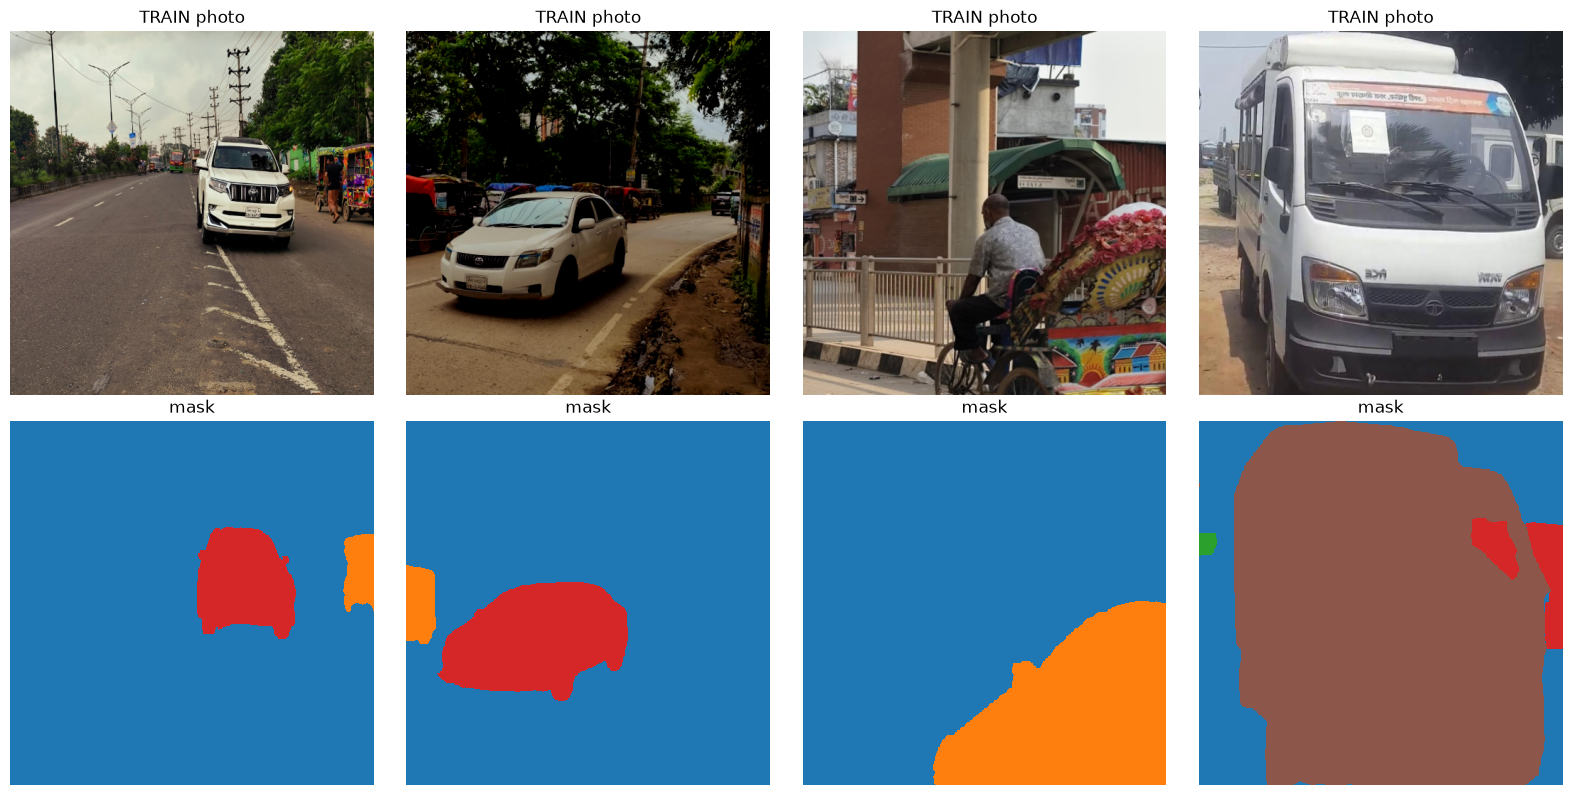

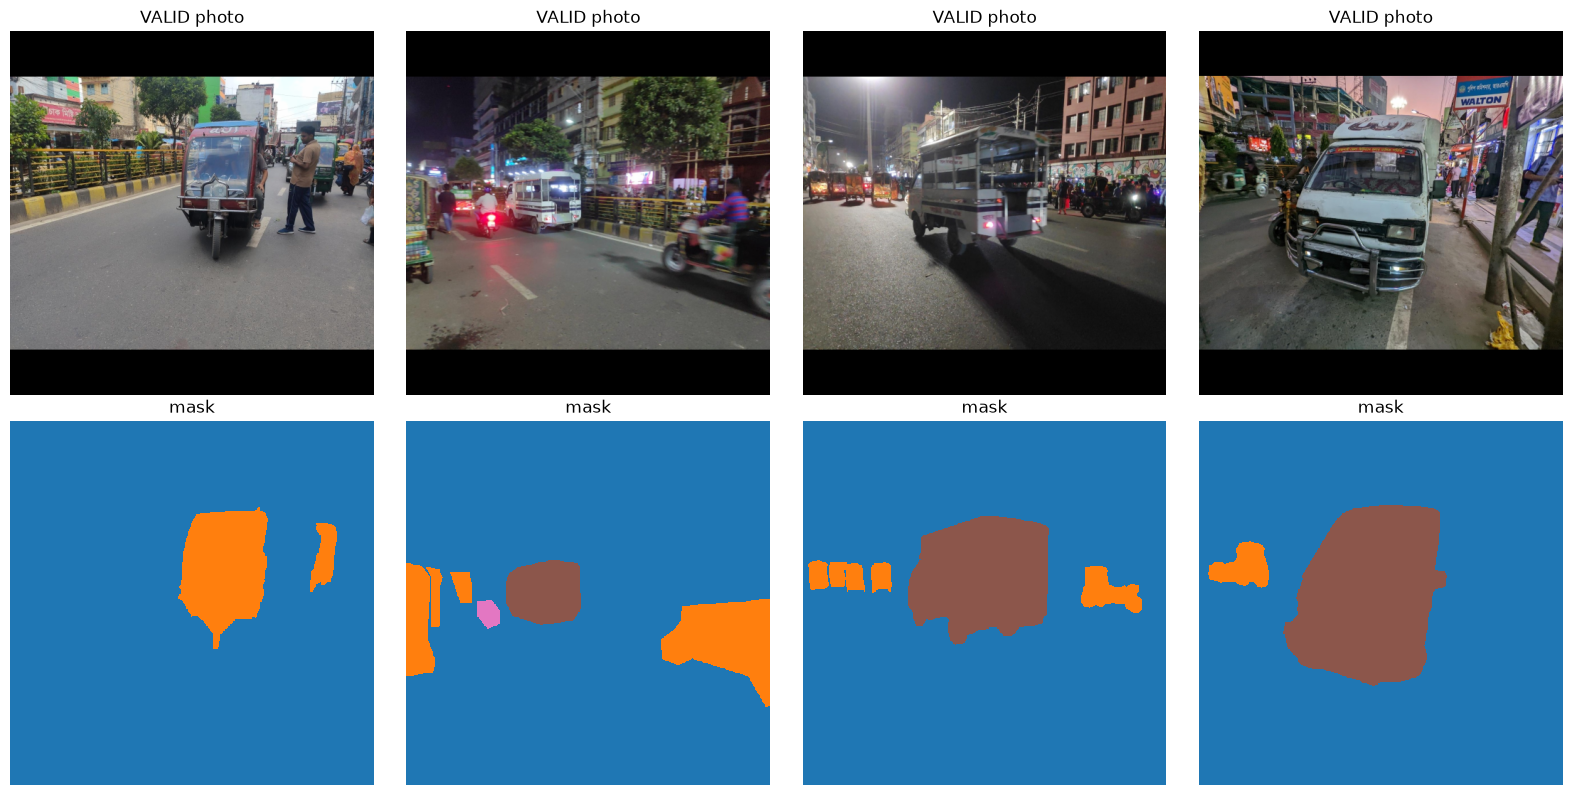

classes: {0: 'background', 1: 'auto_rickshaw', 2: 'bus', 3: 'car', 4: 'cng', 5: 'leguna', 6: 'motorcycle', 7: 'truck'}


In [28]:
# ===== Cell 3e: look at real samples (the best way to catch mistakes) =====
import matplotlib.pyplot as plt

mean = np.array(IMAGENET_MEAN).reshape(3, 1, 1)
std  = np.array(IMAGENET_STD).reshape(3, 1, 1)

def show(loader, title, n=4):
    x, y = next(iter(loader))
    fig, ax = plt.subplots(2, n, figsize=(4 * n, 8))
    for i in range(n):
        img = (x[i].numpy() * std + mean).clip(0, 1)          # undo normalization so colours look normal
        ax[0, i].imshow(img.transpose(1, 2, 0)); ax[0, i].set_title(f"{title} photo"); ax[0, i].axis("off")
        ax[1, i].imshow(y[i].numpy(), cmap="tab10", vmin=0, vmax=9, interpolation="nearest")  # one colour per class
        ax[1, i].set_title("mask"); ax[1, i].axis("off")
    plt.tight_layout(); plt.show()

show(train_loader, "TRAIN")     # random crops and flips
show(valid_loader, "VALID")     # whole photo with padding bars
print("classes:", dict(enumerate(CLASS_NAMES)))

In [29]:
# ===== Cell 3f: run one full pass over the train loader =====
# Two goals: (1) measure how fast the loader is, (2) confirm that no mask value
# outside 0..7 ever appears after augmentation.
import time
from tqdm.auto import tqdm

seen_values = set()
t0 = time.time()
for x, y in tqdm(train_loader, desc="train pass"):     # bar shows batches done and speed
    seen_values.update(torch.unique(y).tolist())

print(f"one epoch of loading: {time.time() - t0:.1f} s")
print("mask values seen:", sorted(seen_values))        # must be exactly 0..7

train pass: 100%|██████████| 119/119 [00:24<00:00,  4.86it/s]

one epoch of loading: 24.5 s
mask values seen: [0, 1, 2, 3, 4, 5, 6, 7]


In [30]:
# ===== Cell 4a: build the model =====
import torch, segmentation_models_pytorch as smp

device = "cuda"
model = smp.Unet(
    encoder_name="mit_b2",        # native smp name (no "tu-" prefix)
    encoder_weights="imagenet",   # pretrained encoder; downloads once
    classes=NUM_CLASSES,          # 8 outputs per pixel
).to(device)

# Check: which top-level parts exist inside the encoder?
print("encoder parts:", [n for n, _ in model.encoder.named_children()])

def n_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if (p.requires_grad or not trainable_only))

print(f"encoder : {n_params(model.encoder)/1e6:.1f} M params")
print(f"decoder : {n_params(model.decoder)/1e6:.1f} M params")
print(f"head    : {n_params(model.segmentation_head)/1e6:.3f} M params")

# Check: model works at our input size
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    out = model(torch.randn(2, 3, 512, 512, device=device))
print("output shape:", tuple(out.shape))     # expect (2, 8, 512, 512)

encoder parts: ['patch_embed1', 'patch_embed2', 'patch_embed3', 'patch_embed4', 'block1', 'norm1', 'block2', 'norm2', 'block3', 'norm3', 'block4', 'norm4']
encoder : 24.2 M params
decoder : 3.3 M params
head    : 0.001 M params
output shape: (2, 8, 512, 512)


In [31]:
# ===== Cell 4b: phase helpers =====
import torch.nn as nn

# Top two encoder stages (stage = patch_embed + block + norm)
TOP_ENCODER = ("patch_embed3", "block3", "norm3", "patch_embed4", "block4", "norm4")

def set_phase(model, phase):
    """Phase 1: encoder fully frozen. Phase 2: only the top stages train."""
    for name, p in model.encoder.named_parameters():
        p.requires_grad = (phase == 2) and name.startswith(TOP_ENCODER)

def make_optimizer(model, phase):
    dec_params = list(model.decoder.parameters()) + list(model.segmentation_head.parameters())
    if phase == 1:
        # decoder + head only
        return torch.optim.AdamW(dec_params, lr=1e-3, weight_decay=1e-2)
    enc_params = [p for p in model.encoder.parameters() if p.requires_grad]
    return torch.optim.AdamW(
        [{"params": enc_params, "lr": 3e-5},      # gentle: keep pretrained knowledge
         {"params": dec_params, "lr": 3e-4}],     # decoder learns faster
        weight_decay=1e-2)

set_phase(model, 1)
print("phase 1 trainable:", f"{n_params(model, True)/1e6:.1f} M")
set_phase(model, 2)
print("phase 2 trainable:", f"{n_params(model, True)/1e6:.1f} M")
set_phase(model, 1)   # back to phase 1

phase 1 trainable: 3.3 M
phase 2 trainable: 24.6 M


In [32]:
# ===== Cell 4c: metrics from a confusion matrix =====
# Confusion matrix: rows = true class, columns = predicted class, summed over
# the WHOLE validation set (not averaged per batch).
def update_confusion(conf, pred, target, C=NUM_CLASSES):
    idx = target.flatten() * C + pred.flatten()
    conf += torch.bincount(idx, minlength=C * C).reshape(C, C)
    return conf

def scores_from_confusion(conf):
    conf = conf.double()
    tp = conf.diag()
    fp = conf.sum(0) - tp          # predicted this class, but wrong
    fn = conf.sum(1) - tp          # missed pixels of this class
    iou  = tp / (tp + fp + fn)
    dice = 2 * tp / (2 * tp + fp + fn)
    return iou.cpu().numpy(), dice.cpu().numpy()   # nan if a class never appears

# quick self-test: a perfect prediction must give IoU = 1
c = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
t = torch.randint(0, NUM_CLASSES, (4, 8, 8))
c = update_confusion(c, t, t)
print("perfect-prediction mIoU:", np.nanmean(scores_from_confusion(c)[0]))   # expect 1.0

perfect-prediction mIoU: 1.0


In [33]:
# ===== Cell 4d: train / validate functions =====
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, criterion, phase, max_batches=None):
    model.train()
    if phase == 1:
        model.encoder.eval()               # frozen encoder: no dropout/drop-path noise
    total, n = 0.0, 0
    for i, (x, y) in enumerate(tqdm(loader, desc="train", leave=False)):
        if max_batches and i >= max_batches: break
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.bfloat16):   # bf16: no GradScaler needed
            logits = model(x)
        loss = criterion(logits, y)                          # loss computed in float32
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # safety against spikes
        optimizer.step()
        total += loss.item(); n += 1
    return total / n

@torch.no_grad()
def validate(model, loader, criterion, max_batches=None):
    model.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    total, n = 0.0, 0
    for i, (x, y) in enumerate(tqdm(loader, desc="valid", leave=False)):
        if max_batches and i >= max_batches: break
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = model(x)
        total += criterion(logits, y).item(); n += 1
        update_confusion(conf, logits.argmax(1), y)
    iou, dice = scores_from_confusion(conf)
    return total / n, float(np.nanmean(iou)), iou, dice

In [34]:
# ===== Cell 4e: tiny test before the real run =====
import copy, time
tmp = copy.deepcopy(model)                 # throwaway copy, real model stays untouched
set_phase(tmp, 1)
opt = make_optimizer(tmp, 1)

t0 = time.time()
l1 = train_one_epoch(tmp, train_loader, opt, criterion, phase=1, max_batches=10)
l2 = train_one_epoch(tmp, train_loader, opt, criterion, phase=1, max_batches=10)
vl, vmiou, _, _ = validate(tmp, valid_loader, criterion, max_batches=5)
print(f"loss first 10 batches: {l1:.3f} | next 10: {l2:.3f} | val loss {vl:.3f} | val mIoU {vmiou:.3f}")
print(f"time: {time.time()-t0:.0f} s | GPU memory used: {torch.cuda.max_memory_allocated()/1e9:.1f} GB")
del tmp, opt; torch.cuda.empty_cache()

loss first 10 batches: 1.369 | next 10: 1.071 | val loss 1.112 | val mIoU 0.169
time: 5 s | GPU memory used: 3.0 GB


In [35]:
# ===== Cell 4f: full training (epochs 1-5 phase 1, epochs 6-30 phase 2) =====
import pandas as pd
from torch.optim.lr_scheduler import CosineAnnealingLR

EPOCHS_P1, EPOCHS_TOTAL = 5, 30
best_miou, history = -1.0, []
BEST_PATH = CKPT_DIR / "best_model.pth"     # /workspace/seg_project/checkpoints/best_model.pth
LAST_PATH = CKPT_DIR / "last_model.pth"

for epoch in range(1, EPOCHS_TOTAL + 1):
    phase = 1 if epoch <= EPOCHS_P1 else 2

    if epoch == 1 or epoch == EPOCHS_P1 + 1:          # entering a new phase
        set_phase(model, phase)
        optimizer = make_optimizer(model, phase)
        scheduler = (CosineAnnealingLR(optimizer, T_max=EPOCHS_TOTAL - EPOCHS_P1, eta_min=1e-6)
                     if phase == 2 else None)         # cosine spans epochs 6-30
        print(f"--- phase {phase}: {n_params(model, True)/1e6:.1f} M trainable params ---")

    tr_loss = train_one_epoch(model, train_loader, optimizer, criterion, phase)
    va_loss, miou, iou, dice = validate(model, valid_loader, criterion)
    if scheduler: scheduler.step()

    lr = optimizer.param_groups[-1]["lr"]
    history.append(dict(epoch=epoch, phase=phase, train_loss=tr_loss,
                        val_loss=va_loss, val_miou=miou, lr=lr))
    pd.DataFrame(history).to_csv(LOG_DIR / "history.csv", index=False)

    torch.save({"model": model.state_dict(), "epoch": epoch, "miou": miou}, LAST_PATH)
    flag = ""
    if miou > best_miou:                               # best = highest val mIoU
        best_miou = miou
        torch.save({"model": model.state_dict(), "epoch": epoch, "miou": miou}, BEST_PATH)
        flag = "  <- best saved"
    print(f"ep {epoch:2d} | P{phase} | train {tr_loss:.3f} | val {va_loss:.3f} | "
          f"mIoU {miou:.4f} | lr {lr:.1e}{flag}")

print("done. best val mIoU:", round(best_miou, 4))

--- phase 1: 3.3 M trainable params ---


ep  1 | P1 | train 0.784 | val 0.463 | mIoU 0.4805 | lr 1.0e-03  <- best saved


ep  2 | P1 | train 0.494 | val 0.405 | mIoU 0.5843 | lr 1.0e-03  <- best saved


ep  3 | P1 | train 0.407 | val 0.355 | mIoU 0.6174 | lr 1.0e-03  <- best saved


ep  4 | P1 | train 0.385 | val 0.340 | mIoU 0.6343 | lr 1.0e-03  <- best saved


ep  5 | P1 | train 0.346 | val 0.295 | mIoU 0.6752 | lr 1.0e-03  <- best saved
--- phase 2: 24.6 M trainable params ---


... (21 outputs left out)

ep 27 | P2 | train 0.098 | val 0.171 | mIoU 0.8141 | lr 1.1e-05  <- best saved


ep 28 | P2 | train 0.098 | val 0.173 | mIoU 0.8139 | lr 5.7e-06


ep 29 | P2 | train 0.100 | val 0.173 | mIoU 0.8145 | lr 2.2e-06  <- best saved


ep 30 | P2 | train 0.094 | val 0.174 | mIoU 0.8145 | lr 1.0e-06
done. best val mIoU: 0.8145


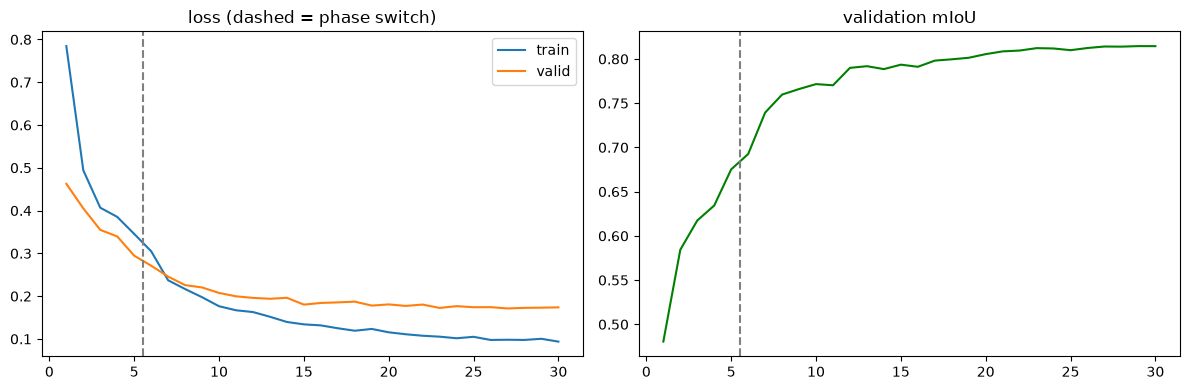

In [36]:
# ===== Cell 4g: plot loss and mIoU =====
import matplotlib.pyplot as plt
h = pd.read_csv(LOG_DIR / "history.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="valid")
ax[0].axvline(5.5, ls="--", c="gray"); ax[0].set_title("loss (dashed = phase switch)"); ax[0].legend()
ax[1].plot(h.epoch, h.val_miou, c="green"); ax[1].axvline(5.5, ls="--", c="gray")
ax[1].set_title("validation mIoU")
plt.tight_layout(); plt.savefig(LOG_DIR / "curves.png", dpi=120); plt.show()